In [1]:
# ==========================================
# STEP 1: IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Regression models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ==========================================
# STEP 2: MOUNT GOOGLE DRIVE
# ==========================================

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==========================================
# STEP 3: LOAD DATASET
# ==========================================

file_path = "/content/drive/MyDrive/MDS_Project/city_day.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (29531, 16)


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# Display first 5 rows

df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [6]:
# Display last 5 rows

df.tail()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory
29530,Visakhapatnam,2020-07-01,15.00,66.00,0.40,26.85,14.05,5.20,0.59,2.10,17.05,NaN,NaN,NaN,50.0,Good


In [7]:
# ==========================================
# CHECK COLUMN NAMES
# ==========================================

print("Columns in dataset:\n")

for i, column in enumerate(df.columns):
    print(i, ":", column)

Columns in dataset:

0 : City
1 : Date
2 : PM2.5
3 : PM10
4 : NO
5 : NO2
6 : NOx
7 : NH3
8 : CO
9 : SO2
10 : O3
11 : Benzene
12 : Toluene
13 : Xylene
14 : AQI
15 : AQI_Bucket


In [8]:
# ==========================================
# DATASET INFORMATION
# ==========================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


In [9]:
# ==========================================
# STATISTICAL SUMMARY
# ==========================================

df.describe()


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [10]:
# ==========================================
# MISSING VALUES
# ==========================================

missing = df.isnull().sum()

missing_percentage = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percentage
})

missing_table = missing_table.sort_values(
    by="Percentage",
    ascending=False
)

missing_table

,Missing Values,Percentage
Xylene,18109,61.322001
PM10,11140,37.723071
NH3,10328,34.973418
Toluene,8041,27.229014
Benzene,5623,19.041008
AQI,4681,15.851139
AQI_Bucket,4681,15.851139
PM2.5,4598,15.570079
NOx,4185,14.171549
O3,4022,13.619586


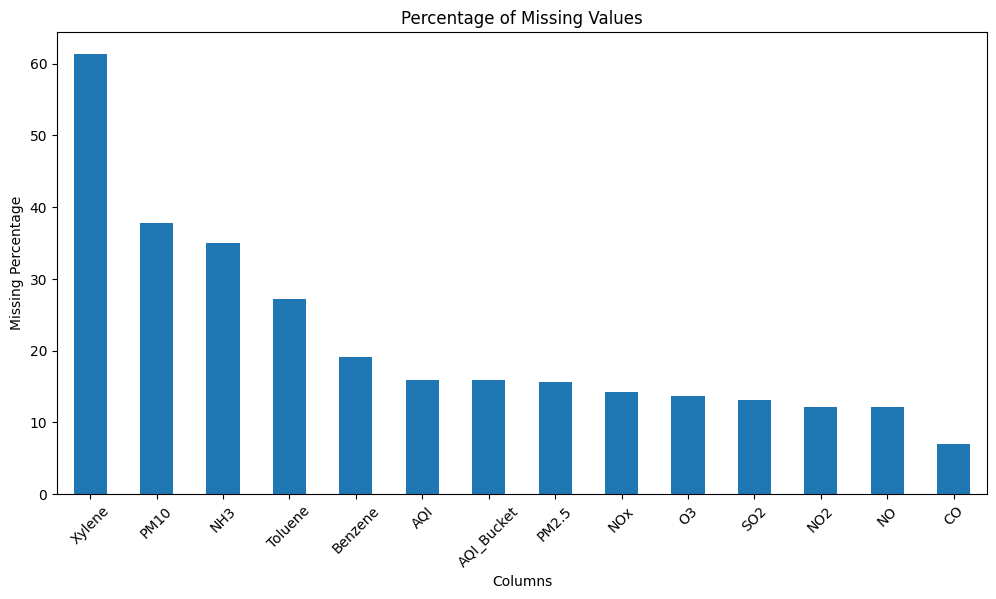

In [11]:
# ==========================================
# MISSING VALUE VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 6))

missing_percentage[missing_percentage > 0].sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Percentage of Missing Values")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage")
plt.xticks(rotation=45)

plt.show()

In [12]:
# ==========================================
# CHECK DUPLICATES
# ==========================================

print("Number of duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Shape after removing duplicates: (29531, 16)


In [13]:
# ==========================================
# CONVERT DATE
# ==========================================

df["Date"] = pd.to_datetime(df["Date"])

print(df["Date"].dtype)

datetime64[ns]


In [14]:
# ==========================================
# DATE FEATURE ENGINEERING
# ==========================================

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek

df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,Year,Month,Day,DayOfWeek
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN,2015,1,1,3
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN,2015,1,2,4
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN,2015,1,3,5
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN,2015,1,4,6
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN,2015,1,5,0


In [15]:
# ==========================================
# CREATE SEASON FEATURE
# ==========================================

def get_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Summer"

    elif month in [6, 7, 8, 9]:
        return "Monsoon"

    else:
        return "Post-Monsoon"


df["Season"] = df["Month"].apply(get_season)

df[["Date", "Month", "Season"]].head(10)

,Date,Month,Season
0,2015-01-01,1,Winter
1,2015-01-02,1,Winter
2,2015-01-03,1,Winter
3,2015-01-04,1,Winter
4,2015-01-05,1,Winter
5,2015-01-06,1,Winter
6,2015-01-07,1,Winter
7,2015-01-08,1,Winter
8,2015-01-09,1,Winter
9,2015-01-10,1,Winter


In [16]:
# ==========================================
# NUMBER OF CITIES
# ==========================================

print("Number of cities:", df["City"].nunique())

print("\nCities:")

print(df["City"].unique())

Number of cities: 26

Cities:
['Ahmedabad' 'Aizawl' 'Amaravati' 'Amritsar' 'Bengaluru' 'Bhopal'
 'Brajrajnagar' 'Chandigarh' 'Chennai' 'Coimbatore' 'Delhi' 'Ernakulam'
 'Gurugram' 'Guwahati' 'Hyderabad' 'Jaipur' 'Jorapokhar' 'Kochi' 'Kolkata'
 'Lucknow' 'Mumbai' 'Patna' 'Shillong' 'Talcher' 'Thiruvananthapuram'
 'Visakhapatnam']


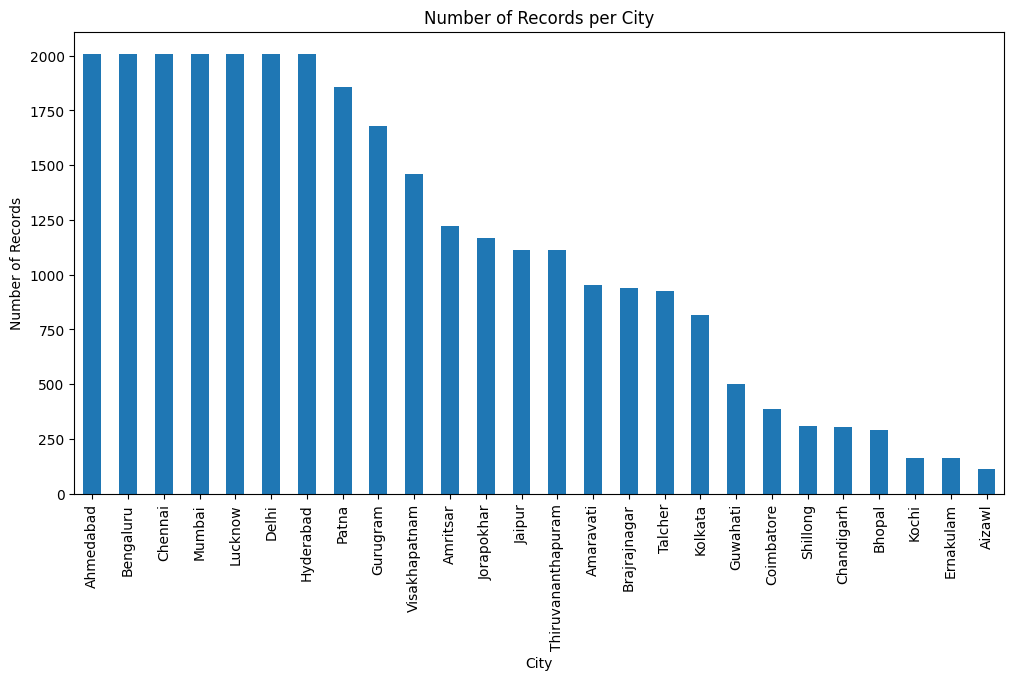

In [17]:
# ==========================================
# RECORDS PER CITY
# ==========================================

city_counts = df["City"].value_counts()

plt.figure(figsize=(12, 6))

city_counts.plot(kind="bar")

plt.title("Number of Records per City")
plt.xlabel("City")
plt.ylabel("Number of Records")

plt.xticks(rotation=90)

plt.show()

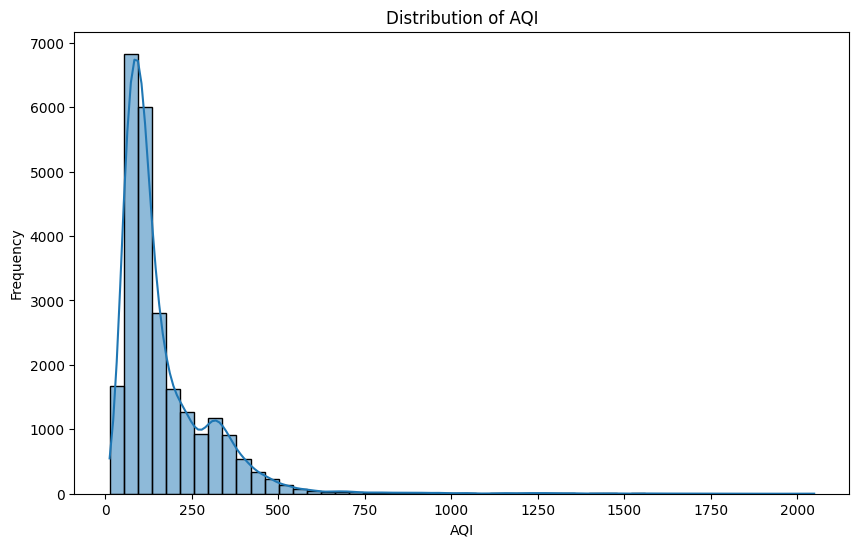

In [18]:
# ==========================================
# AQI DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    df["AQI"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.show()

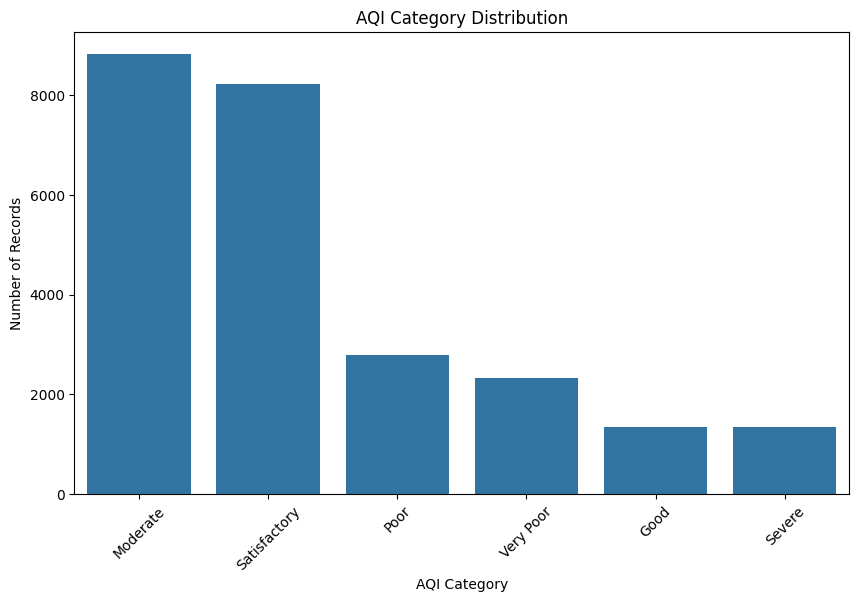

In [19]:
# ==========================================
# AQI CATEGORY DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="AQI_Bucket",
    order=df["AQI_Bucket"].value_counts().index
)

plt.title("AQI Category Distribution")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

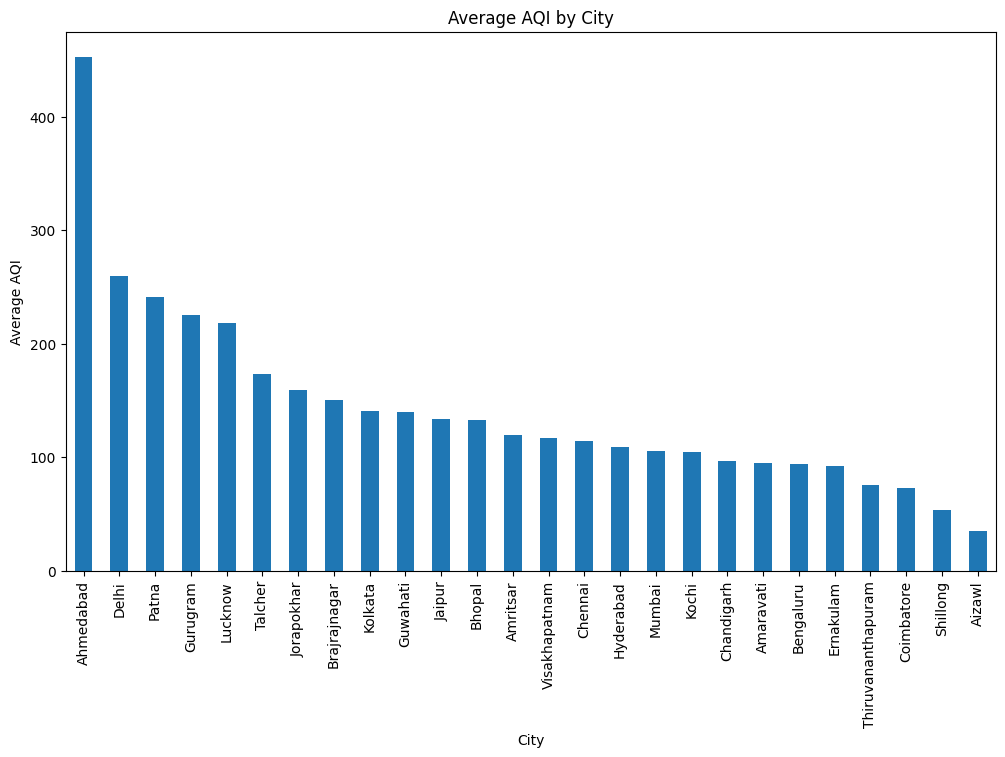

In [20]:
# ==========================================
# AVERAGE AQI BY CITY
# ==========================================

city_aqi = (
    df.groupby("City")["AQI"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

city_aqi.plot(kind="bar")

plt.title("Average AQI by City")
plt.xlabel("City")
plt.ylabel("Average AQI")

plt.xticks(rotation=90)

plt.show()

In [21]:
print("Top 10 cities with highest average AQI:\n")

print(city_aqi.head(10))

Top 10 cities with highest average AQI:

City
Ahmedabad       452.122939
Delhi           259.487744
Patna           240.782042
Gurugram        225.123882
Lucknow         217.973059
Talcher         172.886819
Jorapokhar      159.251621
Brajrajnagar    150.280505
Kolkata         140.566313
Guwahati        140.111111
Name: AQI, dtype: float64


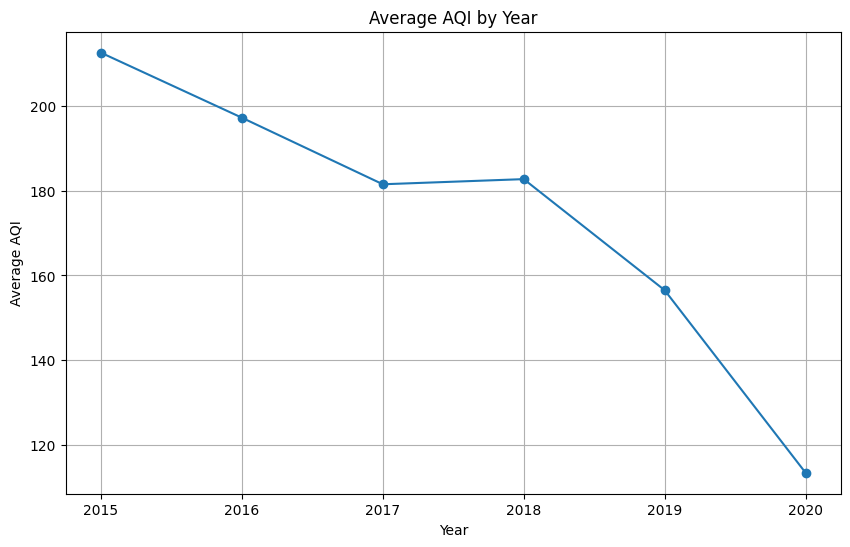

In [22]:
# ==========================================
# AQI TREND BY YEAR
# ==========================================

yearly_aqi = df.groupby("Year")["AQI"].mean()

plt.figure(figsize=(10, 6))

yearly_aqi.plot(marker="o")

plt.title("Average AQI by Year")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.grid(True)

plt.show()

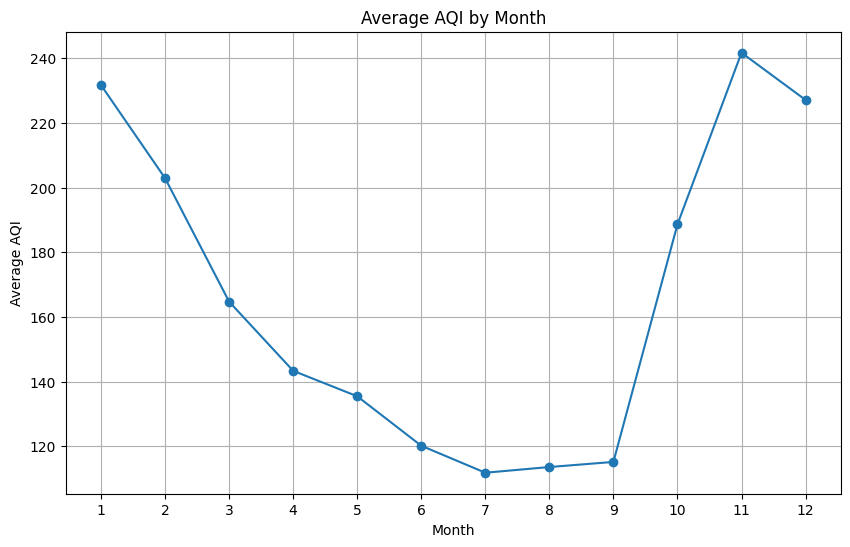

In [23]:
# ==========================================
# MONTHLY AQI
# ==========================================

monthly_aqi = df.groupby("Month")["AQI"].mean()

plt.figure(figsize=(10, 6))

monthly_aqi.plot(marker="o")

plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")

plt.xticks(range(1, 13))

plt.grid(True)

plt.show()

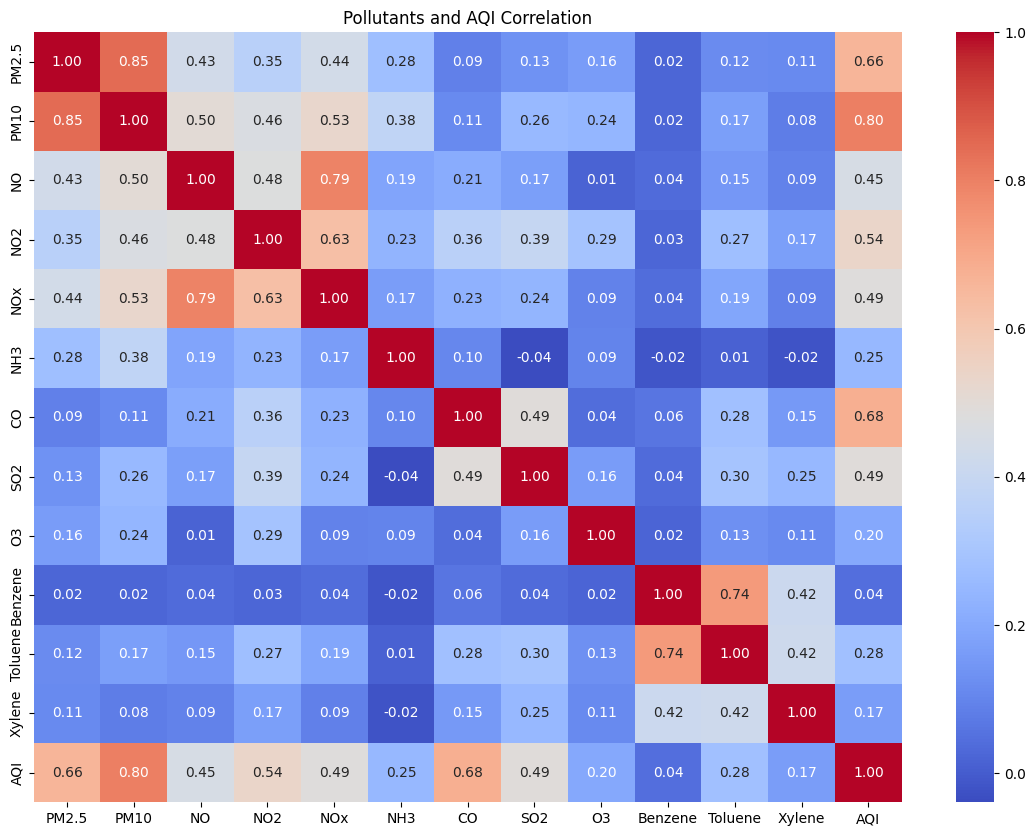

In [24]:
# ==========================================
# CORRELATION MATRIX
# ==========================================

pollutant_columns = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene",
    "AQI"
]

correlation = df[pollutant_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Pollutants and AQI Correlation")

plt.show()

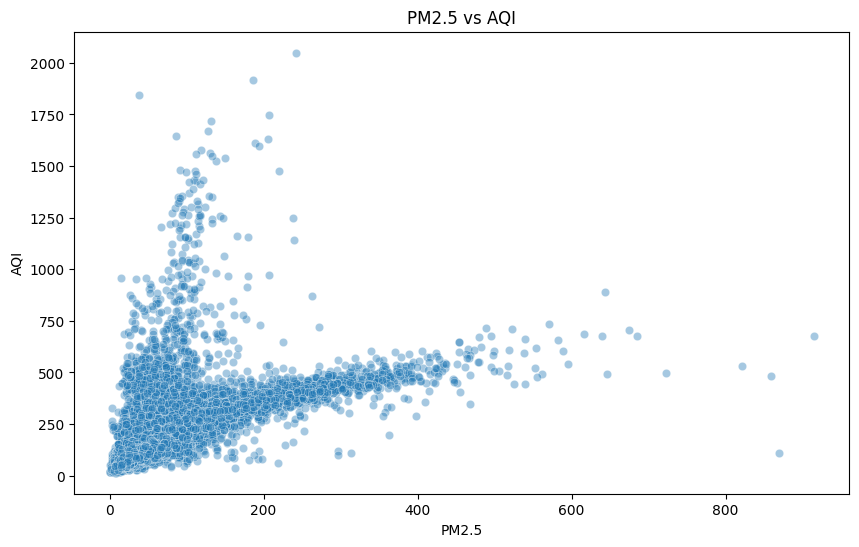

In [25]:
# ==========================================
# PM2.5 VS AQI
# ==========================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="PM2.5",
    y="AQI",
    alpha=0.4
)

plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5")
plt.ylabel("AQI")

plt.show()

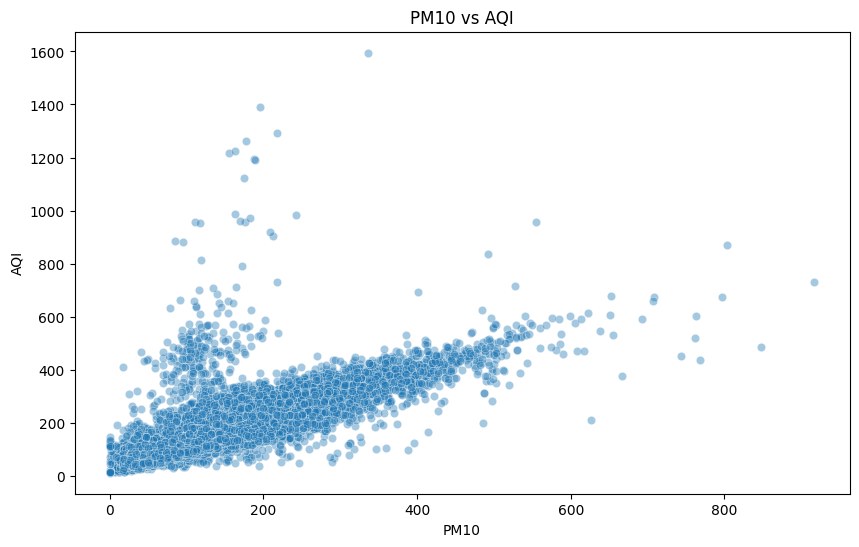

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="PM10",
    y="AQI",
    alpha=0.4
)

plt.title("PM10 vs AQI")
plt.xlabel("PM10")
plt.ylabel("AQI")

plt.show()

In [27]:
# ==========================================
# PREPARE REGRESSION DATA
# ==========================================

regression_df = df.copy()

# Remove rows where target AQI is missing
regression_df = regression_df.dropna(subset=["AQI"])

print("Regression dataset shape:", regression_df.shape)

Regression dataset shape: (24850, 21)


In [28]:
# ==========================================
# SELECT FEATURES
# ==========================================

features = [
    "City",
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "Season",
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene"
]

X = regression_df[features]

y = regression_df["AQI"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (24850, 18)
y shape: (24850,)


In [29]:
# ==========================================
# TIME-BASED SPLIT
# ==========================================

regression_df = regression_df.sort_values("Date")

n = len(regression_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = regression_df.iloc[:train_end]
val_df = regression_df.iloc[train_end:val_end]
test_df = regression_df.iloc[val_end:]

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nDate ranges:")

print("Training:",
      train_df["Date"].min(),
      "to",
      train_df["Date"].max())

print("Validation:",
      val_df["Date"].min(),
      "to",
      val_df["Date"].max())

print("Testing:",
      test_df["Date"].min(),
      "to",
      test_df["Date"].max())

Training: (17395, 21)
Validation: (3727, 21)
Testing: (3728, 21)

Date ranges:
Training: 2015-01-01 00:00:00 to 2019-08-09 00:00:00
Validation: 2019-08-09 00:00:00 to 2020-01-31 00:00:00
Testing: 2020-01-31 00:00:00 to 2020-07-01 00:00:00


In [30]:
X_train = train_df[features]
y_train = train_df["AQI"]

X_val = val_df[features]
y_val = val_df["AQI"]

X_test = test_df[features]
y_test = test_df["AQI"]

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(17395, 18)
(3727, 18)
(3728, 18)


In [31]:
# ==========================================
# PREPROCESSING
# ==========================================

numeric_features = [
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene"
]

categorical_features = [
    "City",
    "Season"
]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [32]:
# ==========================================
# LINEAR REGRESSION
# ==========================================

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

val_pred = linear_model.predict(X_val)

mae = mean_absolute_error(y_val, val_pred)
rmse = np.sqrt(mean_squared_error(y_val, val_pred))
r2 = r2_score(y_val, val_pred)

print("Linear Regression")
print("-------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R2  :", r2)

Linear Regression
-------------------------
MAE : 29.827202035979862
RMSE: 43.624949588497905
R2  : 0.8746608603996647


In [33]:
# ==========================================
# RANDOM FOREST REGRESSION
# ==========================================

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

val_pred_rf = rf_model.predict(X_val)

mae_rf = mean_absolute_error(y_val, val_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_val, val_pred_rf))
r2_rf = r2_score(y_val, val_pred_rf)

print("Random Forest Regression")
print("-------------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R2  :", r2_rf)

Random Forest Regression
-------------------------
MAE : 19.315351489133352
RMSE: 36.2451958578376
R2  : 0.9134797561720799


In [ ]:
# ==========================================
# GRADIENT BOOSTING REGRESSION
# ==========================================

gb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

gb_model.fit(X_train, y_train)

val_pred_gb = gb_model.predict(X_val)

mae_gb = mean_absolute_error(y_val, val_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_val, val_pred_gb))
r2_gb = r2_score(y_val, val_pred_gb)

print("Gradient Boosting Regression")
print("-------------------------")
print("MAE :", mae_gb)
print("RMSE:", rmse_gb)
print("R2  :", r2_gb)

In [ ]:
# ==========================================
# REGRESSION MODEL COMPARISON
# ==========================================
#For regression:

#Lower MAE/RMSE = better

#Higher R² = better

regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse,
        rmse_rf,
        rmse_gb
    ],
    "R2": [
        r2,
        r2_rf,
        r2_gb
    ]
})

regression_results



In [ ]:
# ==========================================
# ACTUAL VS PREDICTED AQI
# ==========================================

best_regression_pred = val_pred_rf

plt.figure(figsize=(8, 8))

plt.scatter(
    y_val,
    best_regression_pred,
    alpha=0.5
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")

plt.title("Actual vs Predicted AQI")

# Perfect prediction line
min_value = min(y_val.min(), best_regression_pred.min())
max_value = max(y_val.max(), best_regression_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

In [ ]:
# ==========================================
# CLASSIFICATION DATASET
# ==========================================

classification_df = df.copy()

# Remove rows where AQI category is missing
classification_df = classification_df.dropna(
    subset=["AQI_Bucket"]
)

print(
    "Classification dataset:",
    classification_df.shape
)

print(
    classification_df["AQI_Bucket"].value_counts()
)

In [ ]:
classification_features = [
    "City",
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "Season",
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene"
]

classification_df = classification_df.sort_values("Date")

X = classification_df[classification_features]

y = classification_df["AQI_Bucket"]

In [ ]:
# ==========================================
# CLASSIFICATION TIME SPLIT
# ==========================================

n = len(classification_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_cls = classification_df.iloc[:train_end]
val_cls = classification_df.iloc[train_end:val_end]
test_cls = classification_df.iloc[val_end:]

X_train_cls = train_cls[classification_features]
y_train_cls = train_cls["AQI_Bucket"]

X_val_cls = val_cls[classification_features]
y_val_cls = val_cls["AQI_Bucket"]

X_test_cls = test_cls[classification_features]
y_test_cls = test_cls["AQI_Bucket"]

print("Training:", X_train_cls.shape)
print("Validation:", X_val_cls.shape)
print("Testing:", X_test_cls.shape)

In [ ]:
# ==========================================
# LOGISTIC REGRESSION
# ==========================================

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=2000
            )
        )
    ]
)

logistic_model.fit(
    X_train_cls,
    y_train_cls
)

pred_logistic = logistic_model.predict(
    X_val_cls
)

accuracy = accuracy_score(
    y_val_cls,
    pred_logistic
)

precision = precision_score(
    y_val_cls,
    pred_logistic,
    average="weighted"
)

recall = recall_score(
    y_val_cls,
    pred_logistic,
    average="weighted"
)

f1 = f1_score(
    y_val_cls,
    pred_logistic,
    average="weighted"
)

print("Logistic Regression")
print("-------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

In [ ]:
# ==========================================
# DECISION TREE CLASSIFIER
# ==========================================

dt_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=10,
                random_state=42
            )
        )
    ]
)

dt_model.fit(
    X_train_cls,
    y_train_cls
)

pred_dt = dt_model.predict(
    X_val_cls
)

accuracy_dt = accuracy_score(
    y_val_cls,
    pred_dt
)

f1_dt = f1_score(
    y_val_cls,
    pred_dt,
    average="weighted"
)

print("Decision Tree")
print("-------------------------")
print("Accuracy:", accuracy_dt)
print("F1 Score:", f1_dt)

In [ ]:
# ==========================================
# RANDOM FOREST CLASSIFIER
# ==========================================

rf_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_classifier.fit(
    X_train_cls,
    y_train_cls
)

pred_rf_cls = rf_classifier.predict(
    X_val_cls
)

accuracy_rf_cls = accuracy_score(
    y_val_cls,
    pred_rf_cls
)

precision_rf_cls = precision_score(
    y_val_cls,
    pred_rf_cls,
    average="weighted"
)

recall_rf_cls = recall_score(
    y_val_cls,
    pred_rf_cls,
    average="weighted"
)

f1_rf_cls = f1_score(
    y_val_cls,
    pred_rf_cls,
    average="weighted"
)

print("Random Forest Classifier")
print("-------------------------")
print("Accuracy :", accuracy_rf_cls)
print("Precision:", precision_rf_cls)
print("Recall   :", recall_rf_cls)
print("F1 Score :", f1_rf_cls)

In [ ]:
# ==========================================
# CLASSIFICATION MODEL COMPARISON
# ==========================================

classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf_cls
    ],
    "F1 Score": [
        f1,
        f1_dt,
        f1_rf_cls
    ]
})

classification_results

In [ ]:
# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_val_cls,
    pred_rf_cls
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
print(
    classification_report(
        y_val_cls,
        pred_rf_cls
    )
)

In [ ]:
depths = [5, 10, 15, 20, None]

depth_results = []

for depth in depths:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", RandomForestClassifier(
                n_estimators=150,
                max_depth=depth,
                random_state=42,
                n_jobs=-1
            ))
        ]
    )

    model.fit(X_train_cls, y_train_cls)

    prediction = model.predict(X_val_cls)

    acc = accuracy_score(y_val_cls, prediction)

    f1_value = f1_score(
        y_val_cls,
        prediction,
        average="weighted"
    )

    depth_results.append([
        depth,
        acc,
        f1_value
    ])

depth_results_df = pd.DataFrame(
    depth_results,
    columns=["max_depth", "Accuracy", "F1"]
)

depth_results_df

In [ ]:
best_row = depth_results_df.loc[
    depth_results_df["F1"].idxmax()
]

print("Best max_depth:", best_row["max_depth"])
print("Best Accuracy:", best_row["Accuracy"])
print("Best F1 Score:", best_row["F1"])

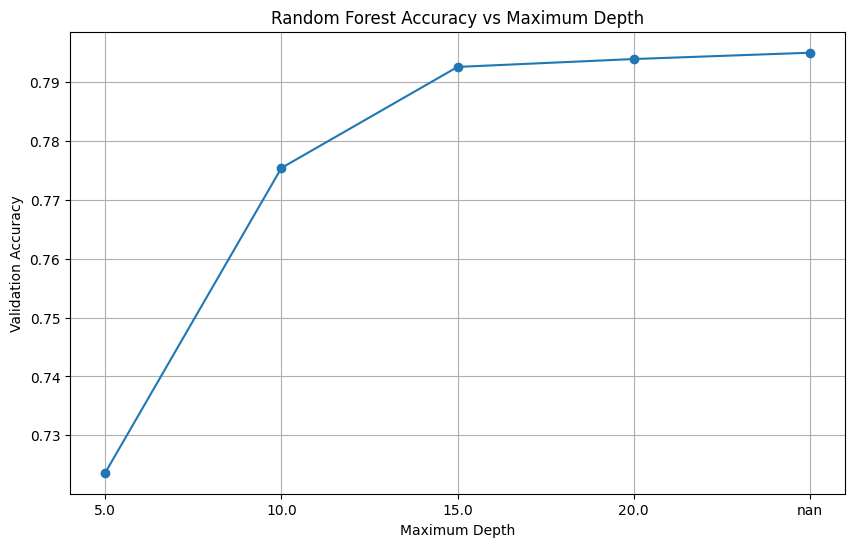

In [48]:
plt.figure(figsize=(10, 6))

plt.plot(
    depth_results_df["max_depth"].astype(str),
    depth_results_df["Accuracy"],
    marker="o"
)

plt.xlabel("Maximum Depth")
plt.ylabel("Validation Accuracy")

plt.title(
    "Random Forest Accuracy vs Maximum Depth"
)

plt.grid(True)

plt.show()

In [49]:
best_row = depth_results_df.loc[
    depth_results_df["F1"].idxmax()
]

print("Best Parameters:")
print(best_row)

Best Parameters:
max_depth         NaN
Accuracy     0.795009
F1           0.789568
Name: 4, dtype: float64


In [50]:
depth_results_df

,max_depth,Accuracy,F1
0,5.0,0.723638,0.686059
1,10.0,0.775423,0.755042
2,15.0,0.792595,0.784388
3,20.0,0.793936,0.787074
4,NaN,0.795009,0.789568


In [51]:
# Select the best row based on validation F1
best_index = depth_results_df["F1"].idxmax()

best_depth = depth_results_df.loc[best_index, "max_depth"]

# Convert NaN back to None
if pd.isna(best_depth):
    best_depth = None
else:
    best_depth = int(best_depth)

print("Selected max_depth:", best_depth)
print("Validation Accuracy:",
      depth_results_df.loc[best_index, "Accuracy"])

print("Validation F1:",
      depth_results_df.loc[best_index, "F1"])

Selected max_depth: None
Validation Accuracy: 0.7950093909310437
Validation F1: 0.7895678112820745


In [52]:
# ==========================================
# FINAL RANDOM FOREST CLASSIFIER
# ==========================================

final_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=best_depth,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train the final model
final_classifier.fit(
    X_train_cls,
    y_train_cls
)

print("Final model trained successfully!")

Final model trained successfully!


In [53]:
# ==========================================
# FINAL TEST PREDICTION
# ==========================================

test_prediction = final_classifier.predict(X_test_cls)

test_accuracy = accuracy_score(
    y_test_cls,
    test_prediction
)

test_precision = precision_score(
    y_test_cls,
    test_prediction,
    average="weighted"
)

test_recall = recall_score(
    y_test_cls,
    test_prediction,
    average="weighted"
)

test_f1 = f1_score(
    y_test_cls,
    test_prediction,
    average="weighted"
)

print("FINAL TEST RESULTS")
print("==========================")

print("Accuracy :", test_accuracy)
print("Precision:", test_precision)
print("Recall   :", test_recall)
print("F1 Score :", test_f1)

FINAL TEST RESULTS
Accuracy : 0.7811158798283262
Precision: 0.800565524459384
Recall   : 0.7811158798283262
F1 Score : 0.7674075875986192


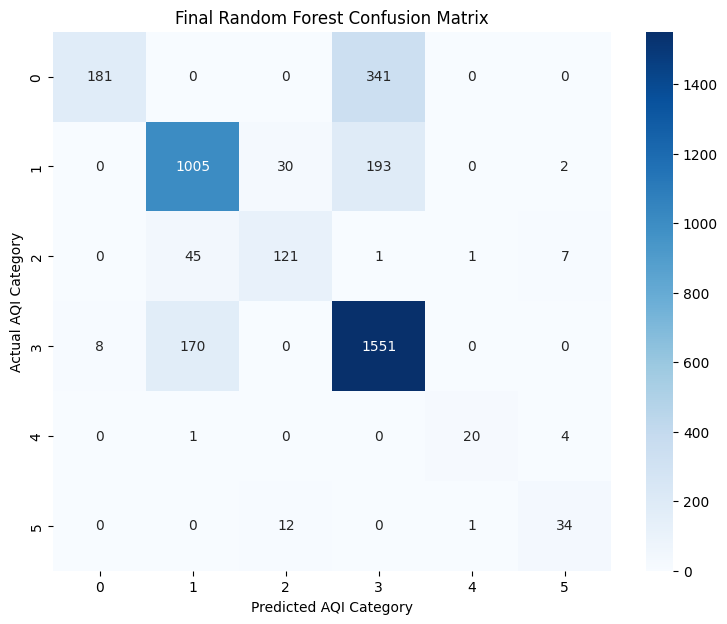

In [54]:
# ==========================================
# FINAL CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_test_cls,
    test_prediction
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Final Random Forest Confusion Matrix")
plt.xlabel("Predicted AQI Category")
plt.ylabel("Actual AQI Category")

plt.show()

In [55]:
# ==========================================
# CLASSIFICATION REPORT
# ==========================================

print(
    classification_report(
        y_test_cls,
        test_prediction
    )
)

              precision    recall  f1-score   support

        Good       0.96      0.35      0.51       522
    Moderate       0.82      0.82      0.82      1230
        Poor       0.74      0.69      0.72       175
Satisfactory       0.74      0.90      0.81      1729
      Severe       0.91      0.80      0.85        25
   Very Poor       0.72      0.72      0.72        47

    accuracy                           0.78      3728
   macro avg       0.82      0.71      0.74      3728
weighted avg       0.80      0.78      0.77      3728



In [56]:
# ==========================================
# BALANCED RANDOM FOREST
# ==========================================

balanced_rf = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=best_depth,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

balanced_rf.fit(
    X_train_cls,
    y_train_cls
)

balanced_prediction = balanced_rf.predict(
    X_test_cls
)

balanced_accuracy = accuracy_score(
    y_test_cls,
    balanced_prediction
)

balanced_precision = precision_score(
    y_test_cls,
    balanced_prediction,
    average="weighted"
)

balanced_recall = recall_score(
    y_test_cls,
    balanced_prediction,
    average="weighted"
)

balanced_f1 = f1_score(
    y_test_cls,
    balanced_prediction,
    average="weighted"
)

print("BALANCED RANDOM FOREST")
print("==============================")
print("Accuracy :", balanced_accuracy)
print("Precision:", balanced_precision)
print("Recall   :", balanced_recall)
print("F1 Score :", balanced_f1)

BALANCED RANDOM FOREST
Accuracy : 0.7459763948497854
Precision: 0.7710685704988389
Recall   : 0.7459763948497854
F1 Score : 0.720223911615025


In [57]:
# ==========================================
# FEATURE IMPORTANCE
# ==========================================

# Get the trained Random Forest
rf_model_final = final_classifier.named_steps["model"]

# Get preprocessing step
preprocessor_final = final_classifier.named_steps["preprocessor"]

# Get feature names after preprocessing
feature_names = preprocessor_final.get_feature_names_out()

# Get importance values
importance_values = rf_model_final.feature_importances_

# Create dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20
feature_importance.head(20)

,Feature,Importance
4,num__PM2.5,0.232618
5,num__PM10,0.123802
10,num__CO,0.088046
6,num__NO,0.053364
12,num__O3,0.052746
7,num__NO2,0.048097
11,num__SO2,0.045927
8,num__NOx,0.045771
14,num__Toluene,0.036987
9,num__NH3,0.035951


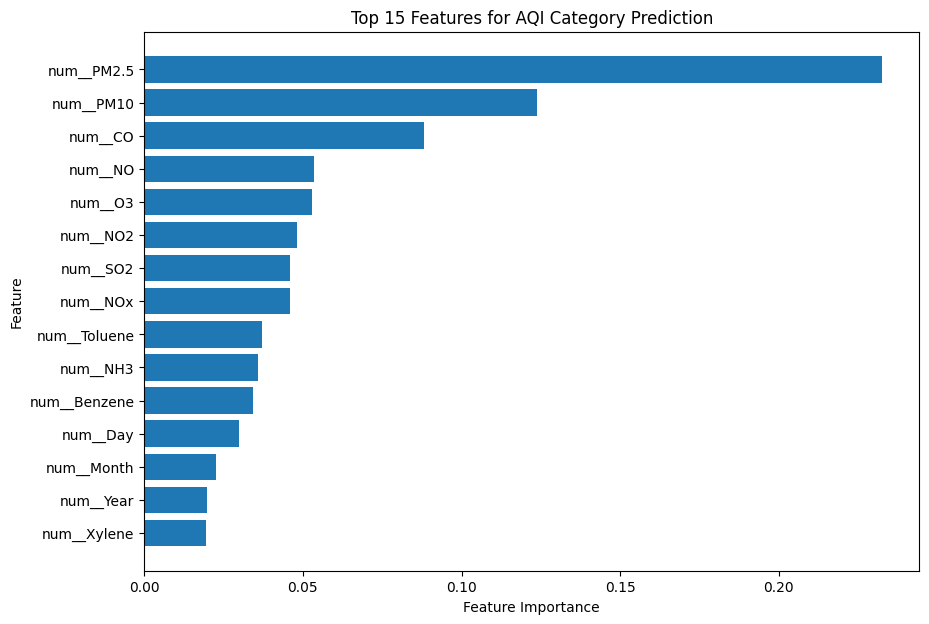

In [58]:
# ==========================================
# TOP 15 FEATURE IMPORTANCE
# ==========================================

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.title(
    "Top 15 Features for AQI Category Prediction"
)

plt.show()

In [59]:
regression_results

,Model,MAE,RMSE,R2
0,Linear Regression,29.827202,43.624950,0.874661
1,Random Forest,19.315351,36.245196,0.913480
2,Gradient Boosting,19.738637,35.113697,0.918797


In [60]:
# ==========================================
# FINAL GRADIENT BOOSTING REGRESSION
# ==========================================

final_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

# Train on training data
final_regressor.fit(
    X_train,
    y_train
)

# Predict test data
test_regression_prediction = final_regressor.predict(
    X_test
)

print("Final regression model trained successfully!")

Final regression model trained successfully!


In [61]:
# ==========================================
# FINAL REGRESSION TEST RESULTS
# ==========================================

test_mae = mean_absolute_error(
    y_test,
    test_regression_prediction
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_regression_prediction
    )
)

test_r2 = r2_score(
    y_test,
    test_regression_prediction
)

print("FINAL REGRESSION TEST RESULTS")
print("==============================")

print("MAE :", test_mae)
print("RMSE:", test_rmse)
print("R²  :", test_r2)

FINAL REGRESSION TEST RESULTS
MAE : 16.472898060533414
RMSE: 26.224243652733204
R²  : 0.8807596198328081


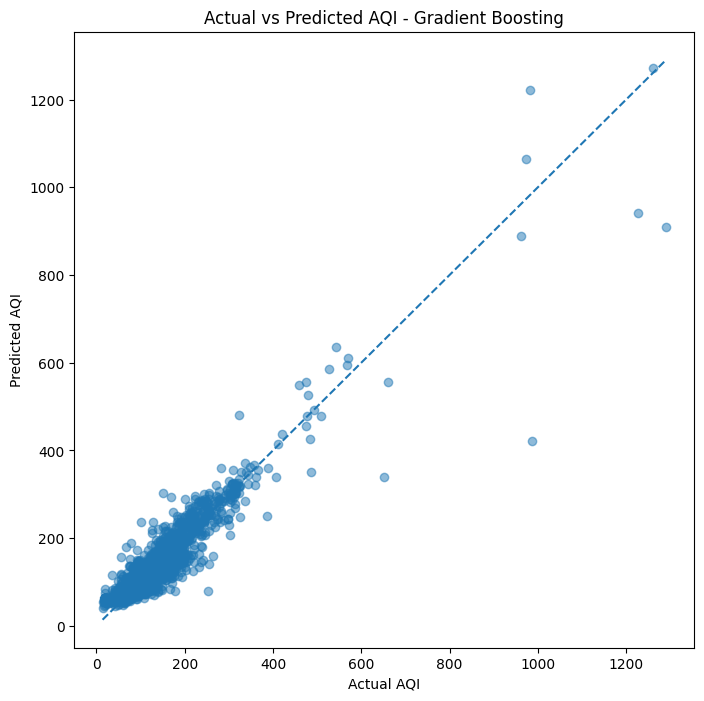

In [62]:
# ==========================================
# ACTUAL VS PREDICTED AQI
# ==========================================

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    test_regression_prediction,
    alpha=0.5
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")

plt.title("Actual vs Predicted AQI - Gradient Boosting")

# Perfect prediction line
min_value = min(
    y_test.min(),
    test_regression_prediction.min()
)

max_value = max(
    y_test.max(),
    test_regression_prediction.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

In [63]:
# ==========================================
# GRADIENT BOOSTING FEATURE IMPORTANCE
# ==========================================

gb_final_model = final_regressor.named_steps["model"]

gb_preprocessor = final_regressor.named_steps["preprocessor"]

# Get feature names after preprocessing
gb_feature_names = gb_preprocessor.get_feature_names_out()

# Get importance
gb_importance_values = gb_final_model.feature_importances_

# Create dataframe
gb_feature_importance = pd.DataFrame({
    "Feature": gb_feature_names,
    "Importance": gb_importance_values
})

# Sort
gb_feature_importance = gb_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20
gb_feature_importance.head(20)

,Feature,Importance
4,num__PM2.5,0.489796
10,num__CO,0.360607
16,cat__City_Ahmedabad,0.043386
5,num__PM10,0.037196
6,num__NO,0.031148
12,num__O3,0.010160
8,num__NOx,0.007453
7,num__NO2,0.005984
15,num__Xylene,0.003213
11,num__SO2,0.002890


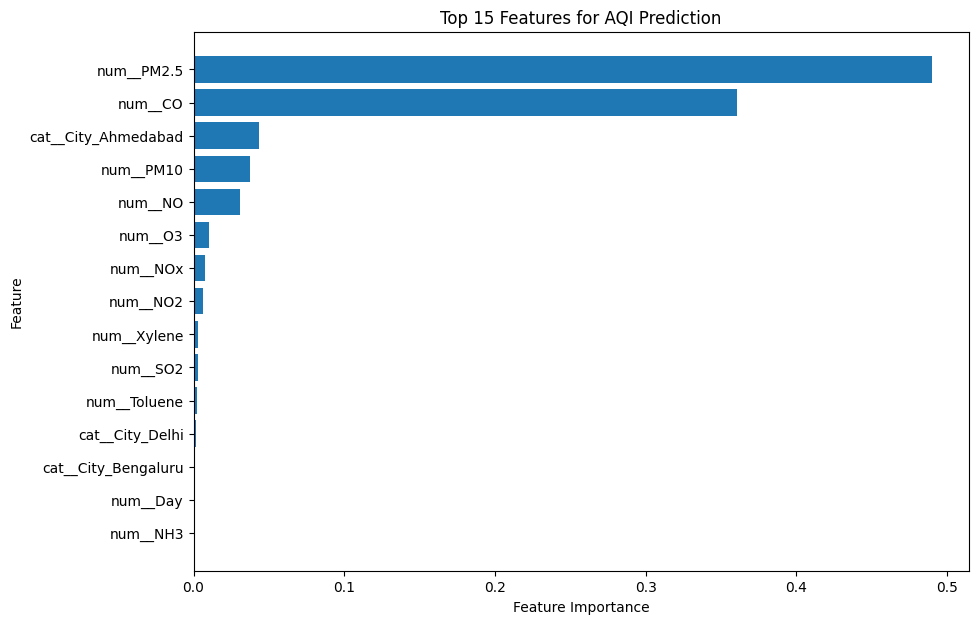

In [64]:
# ==========================================
# TOP 15 REGRESSION FEATURES
# ==========================================

top_gb_features = gb_feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_gb_features["Feature"][::-1],
    top_gb_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.title(
    "Top 15 Features for AQI Prediction"
)

plt.show()

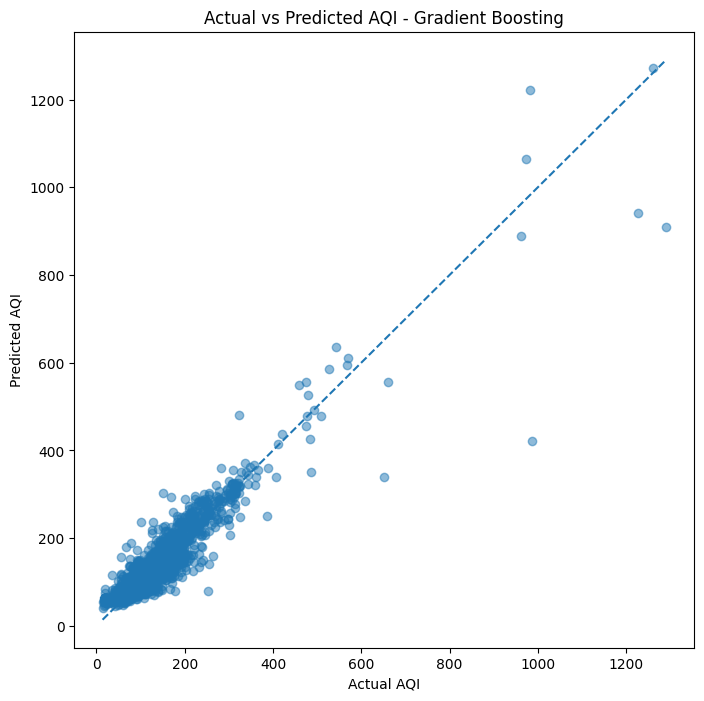

In [65]:
# ==========================================
# ACTUAL VS PREDICTED AQI
# ==========================================

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    test_regression_prediction,
    alpha=0.5
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")

plt.title("Actual vs Predicted AQI - Gradient Boosting")

# Perfect prediction line
min_value = min(
    y_test.min(),
    test_regression_prediction.min()
)

max_value = max(
    y_test.max(),
    test_regression_prediction.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

In [66]:
import joblib

joblib.dump(
    final_classifier,
    "/content/drive/MyDrive/aqi_classification_model.pkl"
)

joblib.dump(
    final_regressor,
    "/content/drive/MyDrive/aqi_regression_model.pkl"
)

print("Models saved successfully!")

Models saved successfully!


In [67]:
final_results = pd.DataFrame({
    "Task": [
        "AQI Regression",
        "AQI Classification"
    ],
    "Final Model": [
        "Gradient Boosting",
        "Random Forest"
    ],
    "Main Metric": [
        "R²",
        "Accuracy"
    ],
    "Test Score": [
        0.8808,
        0.7811
    ]
})

final_results

,Task,Final Model,Main Metric,Test Score
0,AQI Regression,Gradient Boosting,R²,0.8808
1,AQI Classification,Random Forest,Accuracy,0.7811


# XGBoost

In [68]:
!pip install xgboost -q
from xgboost import XGBRegressor

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [69]:
# ==========================================
# XGBOOST REGRESSION
# ==========================================

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("model", XGBRegressor(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


In [70]:
# ==========================================
# TRAIN XGBOOST MODEL
# ==========================================

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [71]:
# ==========================================
# XGBOOST VALIDATION PREDICTION
# ==========================================

val_pred_xgb = xgb_model.predict(X_val)

mae_xgb = mean_absolute_error(y_val, val_pred_xgb)

rmse_xgb = np.sqrt(
    mean_squared_error(y_val, val_pred_xgb)
)

r2_xgb = r2_score(y_val, val_pred_xgb)

print("XGBOOST REGRESSION RESULTS")
print("============================")
print("MAE :", mae_xgb)
print("RMSE:", rmse_xgb)
print("R²  :", r2_xgb)

XGBOOST REGRESSION RESULTS
MAE : 19.74476647588117
RMSE: 40.31479810358056
R²  : 0.8929600712612227


In [72]:
# ==========================================
# CREATE UPDATED REGRESSION RESULTS TABLE
# ==========================================

regression_results_updated = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],

    "MAE": [
        mae,
        mae_rf,
        mae_gb,
        mae_xgb
    ],

    "RMSE": [
        rmse,
        rmse_rf,
        rmse_gb,
        rmse_xgb
    ],

    "R2": [
        r2,
        r2_rf,
        r2_gb,
        r2_xgb
    ]
})

regression_results_updated = regression_results_updated.sort_values(
    by="R2",
    ascending=False
)

print(regression_results_updated)

               Model        MAE       RMSE        R2
2  Gradient Boosting  19.738637  35.113697  0.918797
1      Random Forest  19.315351  36.245196  0.913480
3            XGBoost  19.744766  40.314798  0.892960
0  Linear Regression  29.827202  43.624950  0.874661


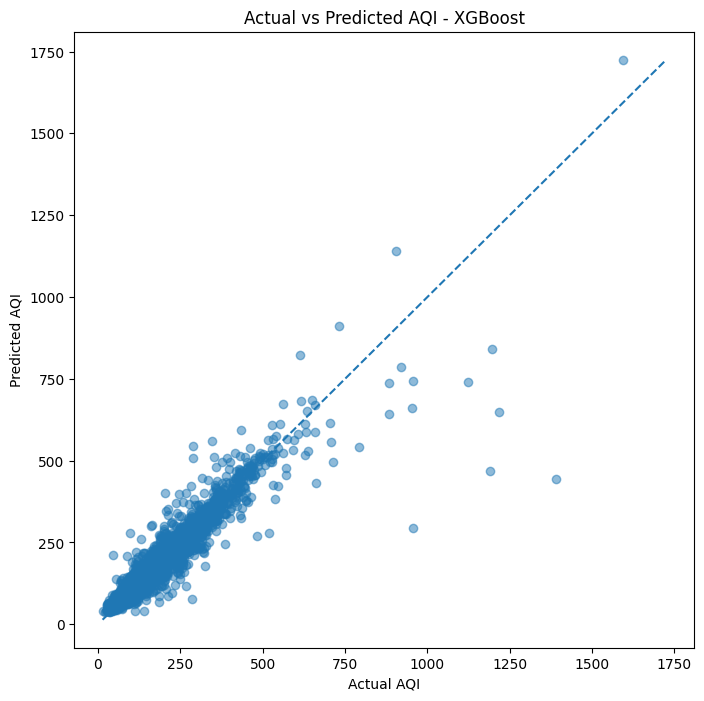

In [73]:
# ==========================================
# XGBOOST ACTUAL VS PREDICTED
# ==========================================

plt.figure(figsize=(8, 8))

plt.scatter(
    y_val,
    val_pred_xgb,
    alpha=0.5
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")

plt.title("Actual vs Predicted AQI - XGBoost")

min_value = min(
    y_val.min(),
    val_pred_xgb.min()
)

max_value = max(
    y_val.max(),
    val_pred_xgb.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

In [74]:
# ==========================================
# FIND BEST REGRESSION MODEL
# ==========================================

best_model_name = regression_results_updated.iloc[0]["Model"]

print("Best Regression Model:")
print(best_model_name)

print("\nBest Model Results:")
print(regression_results_updated.iloc[0])

Best Regression Model:
Gradient Boosting

Best Model Results:
Model    Gradient Boosting
MAE              19.738637
RMSE             35.113697
R2                0.918797
Name: 2, dtype: object


# **SVM**

In [75]:
# ==========================================
# SUPPORT VECTOR MACHINE (SVM) CLASSIFIER
# ==========================================

from sklearn.svm import SVC

svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale"
            )
        )
    ]
)

# Train the SVM model
svm_model.fit(X_train_cls, y_train_cls)

# Validation predictions
pred_svm = svm_model.predict(X_val_cls)

# Evaluation
accuracy_svm = accuracy_score(y_val_cls, pred_svm)
precision_svm = precision_score(
    y_val_cls,
    pred_svm,
    average="weighted"
)
recall_svm = recall_score(
    y_val_cls,
    pred_svm,
    average="weighted"
)
f1_svm = f1_score(
    y_val_cls,
    pred_svm,
    average="weighted"
)

print("Support Vector Machine (SVM)")
print("-------------------------")
print("Accuracy :", accuracy_svm)
print("Precision:", precision_svm)
print("Recall   :", recall_svm)
print("F1 Score :", f1_svm)

Support Vector Machine (SVM)
-------------------------
Accuracy : 0.7013683928092299
Precision: 0.6575010915700414
Recall   : 0.7013683928092299
F1 Score : 0.6680207321632374


# **KNN**

In [76]:
# ==========================================
# K-NEAREST NEIGHBORS (KNN)
# ==========================================

from sklearn.neighbors import KNeighborsClassifier

# Numeric preprocessing with scaling
numeric_transformer_scaled = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer_scaled = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

knn_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_scaled, numeric_features),
        ("cat", categorical_transformer_scaled, categorical_features)
    ]
)

knn_model = Pipeline(
    steps=[
        ("preprocessor", knn_preprocessor),
        (
            "model",
            KNeighborsClassifier(
                n_neighbors=5,
                weights="distance"
            )
        )
    ]
)

# Train
knn_model.fit(X_train_cls, y_train_cls)

# Validation prediction
pred_knn = knn_model.predict(X_val_cls)

# Evaluation
accuracy_knn = accuracy_score(
    y_val_cls,
    pred_knn
)

precision_knn = precision_score(
    y_val_cls,
    pred_knn,
    average="weighted"
)

recall_knn = recall_score(
    y_val_cls,
    pred_knn,
    average="weighted"
)

f1_knn = f1_score(
    y_val_cls,
    pred_knn,
    average="weighted"
)

print("K-Nearest Neighbors")
print("-------------------------")
print("Accuracy :", accuracy_knn)
print("Precision:", precision_knn)
print("Recall   :", recall_knn)
print("F1 Score :", f1_knn)

K-Nearest Neighbors
-------------------------
Accuracy : 0.6198014488865039
Precision: 0.613984642284646
Recall   : 0.6198014488865039
F1 Score : 0.6115263787168282


# **Naive Bayes**

In [77]:
# ==========================================
# GAUSSIAN NAIVE BAYES
# ==========================================

from sklearn.naive_bayes import GaussianNB

nb_numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

nb_categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

nb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", nb_numeric_transformer, numeric_features),
        ("cat", nb_categorical_transformer, categorical_features)
    ]
)

nb_model = Pipeline(
    steps=[
        ("preprocessor", nb_preprocessor),
        ("model", GaussianNB())
    ]
)

# Train
nb_model.fit(X_train_cls, y_train_cls)

# Validation prediction
pred_nb = nb_model.predict(X_val_cls)

# Evaluation
accuracy_nb = accuracy_score(
    y_val_cls,
    pred_nb
)

precision_nb = precision_score(
    y_val_cls,
    pred_nb,
    average="weighted"
)

recall_nb = recall_score(
    y_val_cls,
    pred_nb,
    average="weighted"
)

f1_nb = f1_score(
    y_val_cls,
    pred_nb,
    average="weighted"
)

print("Gaussian Naive Bayes")
print("-------------------------")
print("Accuracy :", accuracy_nb)
print("Precision:", precision_nb)
print("Recall   :", recall_nb)
print("F1 Score :", f1_nb)

Gaussian Naive Bayes
-------------------------
Accuracy : 0.3021196672927287
Precision: 0.5548090725569399
Recall   : 0.3021196672927287
F1 Score : 0.3363307247358692


# **Gradient Boosting Classifier**

In [79]:
# ==========================================
# GRADIENT BOOSTING CLASSIFIER
# ==========================================

from sklearn.ensemble import GradientBoostingClassifier

gb_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingClassifier(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

# Train
gb_classifier.fit(X_train_cls, y_train_cls)

# Validation prediction
pred_gb_cls = gb_classifier.predict(X_val_cls)

# Evaluation
accuracy_gb_cls = accuracy_score(
    y_val_cls,
    pred_gb_cls
)

precision_gb_cls = precision_score(
    y_val_cls,
    pred_gb_cls,
    average="weighted"
)

recall_gb_cls = recall_score(
    y_val_cls,
    pred_gb_cls,
    average="weighted"
)

f1_gb_cls = f1_score(
    y_val_cls,
    pred_gb_cls,
    average="weighted"
)

print("Gradient Boosting Classifier")
print("-------------------------")
print("Accuracy :", accuracy_gb_cls)
print("Precision:", precision_gb_cls)
print("Recall   :", recall_gb_cls)
print("F1 Score :", f1_gb_cls)

Gradient Boosting Classifier
-------------------------
Accuracy : 0.8011805741883552
Precision: 0.7996647514010394
Recall   : 0.8011805741883552
F1 Score : 0.7964510439646455


# **Comparison table**

In [80]:
# ==========================================
# COMPLETE CLASSIFICATION MODEL COMPARISON
# ==========================================

classification_results_all = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "Gradient Boosting",
        "KNN",
        "Naive Bayes"
    ],

    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf_cls,
        accuracy_svm,
        accuracy_gb_cls,
        accuracy_knn,
        accuracy_nb
    ],

    "Precision": [
        precision,
        precision_score(y_val_cls, pred_dt, average="weighted"),
        precision_rf_cls,
        precision_svm,
        precision_gb_cls,
        precision_knn,
        precision_nb
    ],

    "Recall": [
        recall,
        recall_score(y_val_cls, pred_dt, average="weighted"),
        recall_rf_cls,
        recall_svm,
        recall_gb_cls,
        recall_knn,
        recall_nb
    ],

    "F1 Score": [
        f1,
        f1_dt,
        f1_rf_cls,
        f1_svm,
        f1_gb_cls,
        f1_knn,
        f1_nb
    ]
})

classification_results_all

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.735176,0.713081,0.735176,0.715042
1,Decision Tree,0.773276,0.773435,0.773276,0.772972
2,Random Forest,0.794204,0.795473,0.794204,0.788545
3,SVM,0.701368,0.657501,0.701368,0.668021
4,Gradient Boosting,0.801181,0.799665,0.801181,0.796451
5,KNN,0.619801,0.613985,0.619801,0.611526
6,Naive Bayes,0.302120,0.554809,0.302120,0.336331


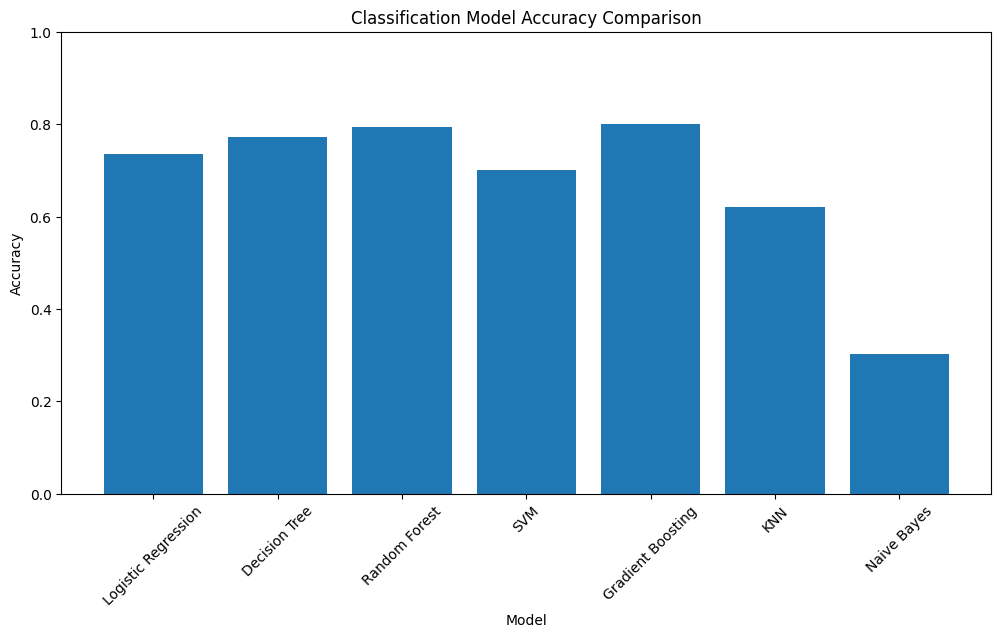

In [81]:
# ==========================================
# MODEL ACCURACY COMPARISON
# ==========================================

plt.figure(figsize=(12, 6))

plt.bar(
    classification_results_all["Model"],
    classification_results_all["Accuracy"]
)

plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.ylim(0, 1)

plt.show()

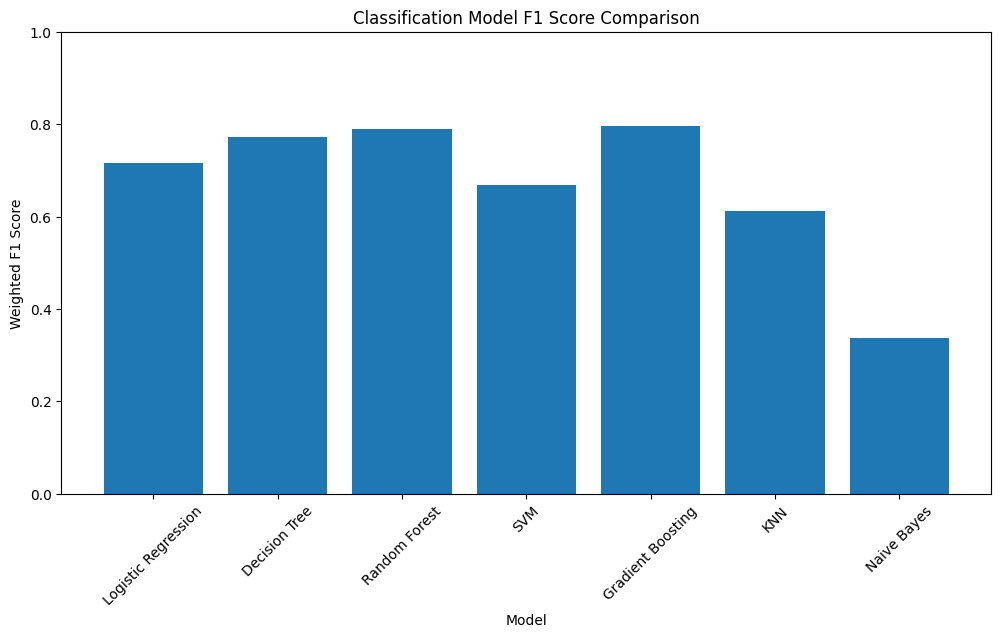

In [82]:
# ==========================================
# MODEL F1 SCORE COMPARISON
# ==========================================

plt.figure(figsize=(12, 6))

plt.bar(
    classification_results_all["Model"],
    classification_results_all["F1 Score"]
)

plt.title("Classification Model F1 Score Comparison")
plt.xlabel("Model")
plt.ylabel("Weighted F1 Score")
plt.xticks(rotation=45)
plt.ylim(0, 1)

plt.show()